

# 01 – Main experiment: five-fold cold-drug cross-validation
**Reproduces:** Section 5.1 (data, partition, training protocol) and Sections 4.1–4.5 (model), Tables 2, 4 and 5, per-cohort test sizes (Supplementary Table S1), Supplementary Tables S5 (structure-level leakage audit) and S6 (baselines with cell-line input), Section 5.8 (Figures 4–6: attention heatmaps, saliency, held-out agreement analysis)

**Responds to:** Reviewer 1 Comments 2 and 4; Reviewer 2 Comments 4 and 5;
Reviewer 3 Comments 2, 4, 5 and 6

**How to run:** `Runtime → Run all`. The default mode, `MODE = "evaluate_saved"` (Cell 2), loads our trained fold models from `checkpoints/cold_drug/`
and re-evaluates them: no training, a CPU runtime is enough (about 20 minutes, most of it the baselines in Cells 14 and 14b).
Set `MODE = "train_and_evaluate"` to retrain from scratch (GPU recommended). Retrained models are written to `checkpoints_retrained/`
and never overwrite ours; retraining gives numbers close to, but not identical with, the reported ones (single seed per fold, non-deterministic GPU operations).

**Reading the output:** lines ending in "(paper: ...)" show the value reported in the manuscript next to the value computed here.
Standard deviations over folds use n−1.



In [ ]:
# ===== Cell 1: Environment =====
# Colab only. The package versions used for the reported results are pinned in requirements.txt.
# RDKit is also pinned here: its canonical SMILES (used for the structure-level audit in Cell 14c) can differ slightly between versions.
!pip install -q rdkit==2026.09.1 matplotlib pubchempy torch torchvision torchaudio torch-geometric transformers xgboost

# Standard library
import io, json, os, sys
from pathlib import Path

# Numerics and data
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy.stats import pearsonr, ttest_rel

# Deep learning
import torch
import torch.nn as nn
import torch.nn.functional as F
from torch.optim.lr_scheduler import ReduceLROnPlateau
from torch.utils.data import Dataset

# Graph learning
from torch_geometric.data import Data, Batch
from torch_geometric.loader import DataLoader
from torch_geometric.nn import GATv2Conv
from torch_geometric.nn.aggr import AttentionalAggregation
from torch_geometric.utils import to_dense_batch

# Chemistry
from rdkit import Chem, RDLogger, Geometry
from rdkit.Chem import AllChem
from rdkit.Chem.Draw import SimilarityMaps, rdMolDraw2D
from PIL import Image
from rdkit.Chem import Draw, rdDepictor


# Pretrained chemical language model (ChemBERTa)
from transformers import AutoTokenizer, AutoModel

# Classical ML and metrics
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import average_precision_score, mean_squared_error, roc_auc_score
from sklearn.preprocessing import StandardScaler
from xgboost import XGBRegressor

RDLogger.DisableLog("rdApp.*")

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 64.4/64.4 kB 6.1 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 31.8/31.8 MB 45.3 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 1.3/1.3 MB 47.1 MB/s eta 0:00:00


In [ ]:
 # ===== Cell 2: Configuration =====
IN_COLAB = "google.colab" in sys.modules
if IN_COLAB and not os.path.ismount("/content/drive"):
    from google.colab import drive
    drive.mount("/content/drive")

# Project folder (see README): on Colab, upload the DualGATSynergy folder to your Drive or change this path.
ROOT = Path("/content/drive/MyDrive/DualGATSynergy") if IN_COLAB else Path(".")
DATA_DIR = ROOT / "data"

# --- Run mode (used in Cells 12 and 13) ---
MODE = "evaluate_saved"          # "evaluate_saved": load our trained models (no training; CPU is fine)
                                 # "train_and_evaluate": retrain from scratch (GPU recommended)
FOLDS_TO_RUN = [1, 2, 3, 4, 5]   # when retraining you may run a single fold, e.g. [1]
CKPT_SHIPPED   = ROOT / "checkpoints" / "cold_drug"             # our trained models (never overwritten)
CKPT_RETRAINED = ROOT / "checkpoints_retrained" / "cold_drug"   # written only when MODE = "train_and_evaluate"
PRED_DIR       = ROOT / "predictions"

SEED = 42
torch.manual_seed(SEED)   # also seeds CUDA
np.random.seed(SEED)
DEVICE = "cuda" if torch.cuda.is_available() else "cpu"
print(f"Mode: {MODE} | device: {DEVICE} | project folder: {ROOT}")

Mounted at /content/drive
Mode: evaluate_saved | device: cpu | project folder: /content/drive/MyDrive/DualGATSynergy


## Data

In [ ]:
# ===== Cell 3: Load and filter the raw data =====
# --- 3.1 DrugComb v1.5 ---
DRUGCOMB_COLS = ["drug_row", "drug_col", "cell_line_name", "synergy_hsa", "study_name", "tissue_name"]
drugcomb_raw = pd.read_csv(DATA_DIR / "drugcomb_full_v1.5.csv", usecols=DRUGCOMB_COLS, low_memory=False)
print(f"Raw records:                 {len(drugcomb_raw):,}   (paper: 1,432,351)")

# Remove non-oncology studies
NON_ONCOLOGY_KEYWORDS = ["malaria", "covid", "sars", "plasmodium", "tuberculosis"]
is_non_oncology = (drugcomb_raw["study_name"].astype(str).str.lower()
                   .str.contains("|".join(NON_ONCOLOGY_KEYWORDS), na=False))
drugcomb_raw = drugcomb_raw[~is_non_oncology].copy()

# Drop records without an HSA score or a cell-line name (removes nothing in v1.5)
drugcomb_raw = drugcomb_raw.dropna(subset=["synergy_hsa", "cell_line_name"])
n_compounds = len(set(drugcomb_raw["drug_row"]) | set(drugcomb_raw["drug_col"]))
print(f"After filtering:             {len(drugcomb_raw):,}   (paper: 1,432,146) | compounds: {n_compounds:,} (paper: 4,608)")

# --- 3.2 Compound -> SMILES cache (resolved through PubChem) ---
cache = pd.read_csv(DATA_DIR / "smiles_cache.csv")        # columns: name, smiles (empty if not resolved)
drug_to_smiles = dict(zip(cache["name"], cache["smiles"]))
known_drugs = {name for name, smi in drug_to_smiles.items() if isinstance(smi, str) and smi}
print(f"Cache: {len(drug_to_smiles)} names, {len(known_drugs)} resolved   (paper: 452 / 418)")

# Keep only records where BOTH compounds have a SMILES string
drugcomb = drugcomb_raw[drugcomb_raw["drug_row"].isin(known_drugs) &
                        drugcomb_raw["drug_col"].isin(known_drugs)].copy()
n_drugs = len(set(drugcomb["drug_row"]) | set(drugcomb["drug_col"]))
print(f"DrugComb subset: {len(drugcomb):,} records, {n_drugs} drugs   (paper: 61,111 / 276)")

# --- 3.3 O'Neil ---
oneil      = pd.read_csv(DATA_DIR / "oneil_summary_idx.csv")
drugs_meta = pd.read_csv(DATA_DIR / "drugs.csv")
cells_meta = pd.read_csv(DATA_DIR / "cell_lines.csv")
drug_map = dict(zip(drugs_meta["id"], drugs_meta["name"]))
cell_map = dict(zip(cells_meta["id"], cells_meta["name"]))
oneil["drug_row"]       = oneil["drug_row_idx"].map(drug_map)
oneil["drug_col"]       = oneil["drug_col_idx"].map(drug_map)
oneil["cell_line_name"] = oneil["cell_line_idx"].map(cell_map)
print(f"O'Neil: {len(oneil):,} records   (paper: 22,737) | unmapped names: "
      f"{int(oneil[['drug_row', 'drug_col', 'cell_line_name']].isna().sum().sum())}")

Raw records:                 1,432,351   (paper: 1,432,351)
After filtering:             1,432,146   (paper: 1,432,146) | compounds: 4,608 (paper: 4,608)
Cache: 452 names, 418 resolved   (paper: 452 / 418)
DrugComb subset: 61,111 records, 276 drugs   (paper: 61,111 / 276)
O'Neil: 22,737 records   (paper: 22,737) | unmapped names: 0


In [ ]:
# ===== Cell 4: O'Neil records with SMILES =====
oneil["smiles_row"] = oneil["drug_row"].map(drug_to_smiles)
oneil["smiles_col"] = oneil["drug_col"].map(drug_to_smiles)
oneil_processed = oneil.dropna(subset=["smiles_row", "smiles_col"])[
    ["drug_row", "drug_col", "smiles_row", "smiles_col", "cell_line_name", "synergy_loewe"]].copy()
oneil_processed.columns = ["drug_1", "drug_2", "smiles_1", "smiles_2", "cell_line", "synergy_score"]
print(f"O'Neil: {len(oneil_processed):,} of {len(oneil):,} records have SMILES for both drugs   (paper: 22,737 of 22,737)")

O'Neil: 22,737 of 22,737 records have SMILES for both drugs   (paper: 22,737 of 22,737)


## Molecular representations: ChemBERTa embeddings and molecular graphs

In [ ]:
# ===== Cell 5: ChemBERTa embeddings (frozen pretrained model, [CLS] token) =====
CHEMBERTA_NAME       = "seyonec/ChemBERTa-zinc-base-v1"
CHEMBERTA_SHIPPED    = DATA_DIR / "drug_to_chemberta.pt"               # 418 compounds x 768 numbers (about 1.3 MB)
CHEMBERTA_RECOMPUTED = DATA_DIR / "drug_to_chemberta_recomputed.pt"    # never overwrites the shipped file
RECOMPUTE_CHEMBERTA  = False   # False: load the shipped file (no download, CPU is fine)
                               # True : recompute with the pretrained model (inference only, no training)

if not RECOMPUTE_CHEMBERTA:
    drug_to_chemberta = torch.load(CHEMBERTA_SHIPPED, map_location="cpu")
else:
    tokenizer = AutoTokenizer.from_pretrained(CHEMBERTA_NAME)
    chemberta = AutoModel.from_pretrained(CHEMBERTA_NAME).eval().to(DEVICE)
    print("Model revision:", getattr(chemberta.config, "_commit_hash", "unknown"))

    @torch.no_grad()
    def chemberta_embedding(smiles):
        """[CLS]-token embedding of one SMILES string (truncated to 128 tokens)."""
        inputs = tokenizer(smiles, return_tensors="pt", padding=True, truncation=True, max_length=128).to(DEVICE)
        return chemberta(**inputs).last_hidden_state[:, 0, :].squeeze(0).cpu()

    drug_to_chemberta = {name: chemberta_embedding(drug_to_smiles[name]) for name in sorted(known_drugs)}
    torch.save(drug_to_chemberta, CHEMBERTA_RECOMPUTED)

CHEMBERTA_DIM = next(iter(drug_to_chemberta.values())).shape[0]
print(f"ChemBERTa embeddings: {len(drug_to_chemberta)} compounds | dim = {CHEMBERTA_DIM}   (paper pipeline: 418 | 768)")
assert set(drug_to_chemberta) == known_drugs, "embedding file and SMILES cache do not match"

ChemBERTa embeddings: 418 compounds | dim = 768   (paper pipeline: 418 | 768)


In [ ]:
# ===== Cell 6: Molecular graphs =====
NODE_FEATURES = ["atomic_number", "degree", "explicit_valence", "implicit_valence", "is_aromatic", "in_ring",
                 "formal_charge", "num_radical_electrons", "hybridization", "chiral_tag", "atomic_mass"]
NODE_DIM, EDGE_DIM = len(NODE_FEATURES), 1      # edge feature: bond order (1.0, 1.5, 2.0 or 3.0)

def _valences(atom):
    """(explicit, implicit) valence. GetExplicitValence/GetImplicitValence produced the reported results;
    newer RDKit versions replace them with GetValence(...)."""
    try:
        return atom.GetExplicitValence(), atom.GetImplicitValence()
    except AttributeError:
        return atom.GetValence(Chem.ValenceType.EXPLICIT), atom.GetValence(Chem.ValenceType.IMPLICIT)

def smiles_to_graph(smiles):
    """SMILES string -> PyG graph (node features: NODE_FEATURES; edge feature: bond order).
    Returns None if the SMILES is missing or cannot be parsed."""
    if not isinstance(smiles, str) or not smiles:
        return None
    mol = Chem.MolFromSmiles(smiles)
    if mol is None:
        return None

    features = []
    for atom in mol.GetAtoms():
        explicit_valence, implicit_valence = _valences(atom)
        features.append([
            atom.GetAtomicNum(),
            atom.GetDegree(),
            explicit_valence,
            implicit_valence,
            int(atom.GetIsAromatic()),
            int(atom.IsInRing()),
            atom.GetFormalCharge(),
            atom.GetNumRadicalElectrons(),
            int(atom.GetHybridization()),
            int(atom.GetChiralTag()),       # RDKit chiral tag (none / clockwise / counter-clockwise / other)
            atom.GetMass(),
        ])
    x = torch.tensor(features, dtype=torch.float)

    edge_index, edge_attr = [], []
    for bond in mol.GetBonds():
        s, e = bond.GetBeginAtomIdx(), bond.GetEndAtomIdx()
        order = bond.GetBondTypeAsDouble()
        edge_index += [(s, e), (e, s)]           # undirected: both directions
        edge_attr  += [order, order]

    if edge_index:
        edge_index = torch.tensor(edge_index, dtype=torch.long).t().contiguous()
        edge_attr  = torch.tensor(edge_attr,  dtype=torch.float).view(-1, 1)
    else:                                         # single-atom molecule
        edge_index = torch.empty((2, 0), dtype=torch.long)
        edge_attr  = torch.empty((0, 1),   dtype=torch.float)
    return Data(x=x, edge_index=edge_index, edge_attr=edge_attr)

# Sanity check on all resolved compounds
graph_check = {name: smiles_to_graph(drug_to_smiles[name]) for name in known_drugs}
n_failed   = sum(g is None for g in graph_check.values())
n_no_bonds = sum(g is not None and g.edge_index.shape[1] == 0 for g in graph_check.values())
print(f"{len(graph_check)} cached compounds | failed to parse: {n_failed} | without any bond: {n_no_bonds} "
      f"(the paper's statement concerns the 309 compounds used in the experiments; see the check after Cell 7)")
assert all(g.x.shape[1] == NODE_DIM for g in graph_check.values() if g is not None)
del graph_check

418 cached compounds | failed to parse: 0 | without any bond: 2 (the paper's statement concerns the 309 compounds used in the experiments; see the check after Cell 7)


## Combined dataset and cold-drug partition

In [ ]:
# ===== Cell 7: Combine DrugComb (HSA) and O'Neil (Loewe) =====
drugcomb_unified = (drugcomb.dropna(subset=["synergy_hsa", "cell_line_name"])
                    [["drug_row", "drug_col", "synergy_hsa", "cell_line_name"]]
                    .rename(columns={"drug_row": "drug_1", "drug_col": "drug_2",
                                     "synergy_hsa": "raw_target", "cell_line_name": "cell_line"}))
drugcomb_unified["dataset_type"] = "drugcomb"

oneil_unified = (oneil_processed.dropna(subset=["synergy_score"])
                 [["drug_1", "drug_2", "synergy_score", "cell_line"]]
                 .rename(columns={"synergy_score": "raw_target"}))
oneil_unified["dataset_type"] = "oneil"

df_combined = pd.concat([drugcomb_unified, oneil_unified], ignore_index=True)

# One integer per cell line (order of first appearance) and the list of all compounds
all_cell_lines   = df_combined["cell_line"].unique()
cell_line_to_idx = {cl: i for i, cl in enumerate(all_cell_lines)}
n_cell_lines     = len(all_cell_lines)
all_drugs        = pd.concat([df_combined["drug_1"], df_combined["drug_2"]]).unique()

print(f"Records: {len(df_combined):,} (paper: 83,848) | cell-line identifiers: {n_cell_lines} (paper: 251) "
      f"| compounds: {len(all_drugs)} (paper: 309)")

Records: 83,848 (paper: 83,848) | cell-line identifiers: 251 (paper: 251) | compounds: 309 (paper: 309)


In [ ]:
no_bond_used = [n for n in sorted(set(all_drugs)) if smiles_to_graph(drug_to_smiles[n]).edge_index.shape[1] == 0]
print(f"Compounds without any bond among the {len(all_drugs)} used compounds: {len(no_bond_used)}   (paper: 0)")
assert not no_bond_used, no_bond_used

Compounds without any bond among the 309 used compounds: 0   (paper: 0)


In [ ]:
single = [n for n in sorted(known_drugs) if smiles_to_graph(drug_to_smiles[n]).edge_index.shape[1] == 0]
print("single-atom compounds:", {n: drug_to_smiles[n] for n in single})
print("among the 309 used compounds:", [n for n in single if n in set(all_drugs)])

single-atom compounds: {'7440-47-3': '[Cr]', 'TRISENOX': '[O-2].[O-2].[O-2].[As+3].[As+3]'}
among the 309 used compounds: []


In [ ]:
a, b = df_combined["drug_1"].astype(str), df_combined["drug_2"].astype(str)
chk = df_combined.assign(pair=np.where(a <= b, a + "|" + b, b + "|" + a), fwd=(a <= b))
print("drug_1 <= drug_2 (alphabetical), share per cohort:\n", chk.groupby("dataset_type")["fwd"].mean().round(3))
print("share of drug pairs seen in BOTH orders:\n", chk.groupby(["dataset_type", "pair"])["fwd"].nunique().eq(2).groupby("dataset_type").mean().round(3))
print("mean standardized label, drug_1 <= drug_2 vs not:", chk.groupby("fwd")["raw_target"].mean().round(2).to_dict())

drug_1 <= drug_2 (alphabetical), share per cohort:
 dataset_type
drugcomb    0.461
oneil       0.494
Name: fwd, dtype: float64
share of drug pairs seen in BOTH orders:
 dataset_type
drugcomb    0.034
oneil       0.000
Name: fwd, dtype: float64
mean standardized label, drug_1 <= drug_2 vs not: {False: 0.3, True: -0.11}


In [ ]:
z = chk.groupby("dataset_type")["raw_target"].transform(lambda s: (s - s.mean()) / s.std())
print(z.groupby([chk["dataset_type"], chk["fwd"]]).mean().round(3))

dataset_type  fwd  
drugcomb      False    0.025
              True    -0.029
oneil         False    0.006
              True    -0.006
Name: raw_target, dtype: float64


In [ ]:
# ===== Cell 8: Five-fold cold-drug partition =====
COHORTS = ["drugcomb", "oneil"]

def standardize_labels(train_df, val_df, test_df, fold):
    """Cohort-wise z-scoring of the synergy score into column 'label'.
    Mean and SD of each cohort come from the TRAINING rows only and are then applied to that cohort's
    validation and test rows, so nothing from validation or test enters the statistics."""
    scalers = {}
    for cohort in COHORTS:
        mask = train_df["dataset_type"] == cohort
        if mask.sum() == 0:
            print(f"  [warn] fold={fold}: no '{cohort}' samples in train -> scaler skipped")
            scalers[cohort] = None
            continue
        scalers[cohort] = StandardScaler()
        train_df.loc[mask, "label"] = scalers[cohort].fit_transform(train_df.loc[mask, ["raw_target"]])
    for split_df, split_name in ((val_df, "val"), (test_df, "test")):
        for cohort in COHORTS:
            mask = split_df["dataset_type"] == cohort
            if mask.sum() == 0:
                continue
            if scalers[cohort] is not None:
                split_df.loc[mask, "label"] = scalers[cohort].transform(split_df.loc[mask, ["raw_target"]])
            else:   # no training statistics for this cohort: its rows cannot be standardized, so they are dropped
                print(f"  [warn] fold={fold}: dropping {mask.sum()} '{cohort}' rows from {split_name} (no train scaler)")
                split_df.drop(split_df[mask].index, inplace=True)
    return scalers


def build_cold_drug_kfold_partition(df_combined, all_drugs, n_folds=5, val_frac=0.15, seed=42):
    """Drugs (not records) are partitioned. All drugs are shuffled once and cut into n_folds disjoint groups;
    each group is the test set of exactly one fold. Within a fold:
      test  = every record containing at least one test drug
      val   = records with a validation drug and no test drug (46 validation drugs, sampled from the non-test drugs)
      train = all other records (no test drug, no validation drug)
    """
    rng = np.random.RandomState(seed)
    shuffled_drugs = rng.permutation(all_drugs)
    test_groups = np.array_split(shuffled_drugs, n_folds)

    folds = []
    for fold_idx, test_drugs_arr in enumerate(test_groups):
        test_drugs = set(test_drugs_arr)
        remaining_drugs = np.array([d for d in all_drugs if d not in test_drugs])
        fold_rng = np.random.RandomState(seed * 1000 + fold_idx)
        n_val = int(val_frac * len(all_drugs))
        val_drugs = set(fold_rng.choice(remaining_drugs, size=min(n_val, len(remaining_drugs)), replace=False))

        is_test_pair  = df_combined["drug_1"].isin(test_drugs) | df_combined["drug_2"].isin(test_drugs)
        is_val_pair   = (~is_test_pair) & (df_combined["drug_1"].isin(val_drugs) | df_combined["drug_2"].isin(val_drugs))
        is_train_pair = ~is_test_pair & ~is_val_pair
        train_df, val_df, test_df = (df_combined[m].copy() for m in (is_train_pair, is_val_pair, is_test_pair))
        scalers = standardize_labels(train_df, val_df, test_df, fold_idx + 1)

        folds.append({"fold": fold_idx + 1, "train_df": train_df, "val_df": val_df, "test_df": test_df,
                      "test_drugs": test_drugs, "val_drugs": val_drugs,
                      "n_test_drugs": len(test_drugs), "n_val_drugs": len(val_drugs), "scalers": scalers})
    return folds


def verify_partition(folds, all_drugs):
    """Every drug must be in exactly one test set (no omissions, no duplicates)."""
    all_test_drugs = [d for f in folds for d in f["test_drugs"]]
    counts = pd.Series(all_test_drugs).value_counts()
    n_never, n_duplicated = len(all_drugs) - len(counts), int((counts > 1).sum())
    print(f"Test coverage: {len(counts)}/{len(all_drugs)} drugs | omitted: {n_never} | duplicated: {n_duplicated}")
    assert n_never == 0 and n_duplicated == 0, "not a true partition"
    print("✓ partition verified: every drug is in exactly one test set.")


def check_or_save_json(path, obj, what):
    """First run: save. Later runs (and reviewers): the rebuilt object must equal the shipped file."""
    path.parent.mkdir(parents=True, exist_ok=True)
    if path.exists():
        assert json.loads(path.read_text(encoding="utf-8")) == obj, f"{what} differs from the shipped file {path.name}"
        print(f"✓ {what} identical to the shipped file")
    else:
        path.write_text(json.dumps(obj, indent=1, ensure_ascii=False), encoding="utf-8")
        print(f"Saved {what} -> {path}")


folds = build_cold_drug_kfold_partition(df_combined, all_drugs, n_folds=5, seed=42)
verify_partition(folds, all_drugs)
check_or_save_json(ROOT / "splits" / "cold_drug_5fold.json",
                   {str(f["fold"]): {"test_drugs": sorted(map(str, f["test_drugs"])),
                                     "val_drugs":  sorted(map(str, f["val_drugs"]))} for f in folds}, "cold-drug split")
check_or_save_json(ROOT / "splits" / "cell_line_to_idx.json",
                   {str(k): int(v) for k, v in cell_line_to_idx.items()}, "cell-line index")

print("\nRecords per partition (compare with Table 2):")
print(pd.DataFrame([{"fold": f["fold"], "train": len(f["train_df"]), "validation": len(f["val_df"]),
                     "test": len(f["test_df"])} for f in folds]).to_string(index=False))

Test coverage: 309/309 drugs | omitted: 0 | duplicated: 0
✓ partition verified: every drug is in exactly one test set.
✓ cold-drug split identical to the shipped file
✓ cell-line index identical to the shipped file

Records per partition (compare with Table 2):
 fold  train  validation  test
    1  31943       16459 35446
    2  44109       12321 27418
    3  31761       20452 31635
    4  37365       16643 29840
    5  33848       22116 27884


## Model, dataset and training code

In [ ]:
# ===== Cell 9: Dataset =====
_mol_graph_cache = {}

def get_cached_graph(smiles):
    """Build each molecular graph once; return a copy so per-sample attributes never leak into the cache."""
    if smiles not in _mol_graph_cache:
        _mol_graph_cache[smiles] = smiles_to_graph(smiles)
    cached = _mol_graph_cache[smiles]
    return cached.clone() if cached is not None else None


class UnifiedSynergyDataset(Dataset):
    """Sample = (graph of drug 1, graph of drug 2, standardized synergy label).
    A record is kept only if both drugs have a ChemBERTa embedding and a SMILES that RDKit can parse."""
    def __init__(self, dataframe, drug_smiles_dict, drug_chemberta_dict, cell_line_to_idx):
        self.data        = dataframe.reset_index(drop=True)
        self.drug_smiles = drug_smiles_dict
        self.drug_cb     = drug_chemberta_dict
        self.cell_to_idx = cell_line_to_idx

        valid_drugs = {name for name in drug_chemberta_dict
                       if isinstance(drug_smiles_dict.get(name), str)
                       and Chem.MolFromSmiles(drug_smiles_dict[name]) is not None}
        keep = self.data["drug_1"].isin(valid_drugs) & self.data["drug_2"].isin(valid_drugs)
        self.valid_indices = list(self.data.index[keep])
        print(f"Valid samples: {len(self.valid_indices):,} of {len(self.data):,}")

    def __len__(self):
        return len(self.valid_indices)

    def __getitem__(self, idx):
        row = self.data.iloc[self.valid_indices[idx]]
        g1 = get_cached_graph(self.drug_smiles[row["drug_1"]])
        g2 = get_cached_graph(self.drug_smiles[row["drug_2"]])
        g1.cb = self.drug_cb[row["drug_1"]].unsqueeze(0)
        g2.cb = self.drug_cb[row["drug_2"]].unsqueeze(0)
        cl_idx = self.cell_to_idx[row["cell_line"]]
        g1.cell_idx = torch.tensor([cl_idx], dtype=torch.long)
        g2.cell_idx = torch.tensor([cl_idx], dtype=torch.long)
        target = torch.tensor(row["label"], dtype=torch.float)
        return g1, g2, target

In [ ]:
# ===== Cell 10: DualGATSynergy =====
class DualGATSynergy(nn.Module):
    def __init__(self, num_atom_features, chemberta_dim, n_cell_lines, hidden_dim=64, heads=2):
        super().__init__()
        # Weight-shared two-layer GATv2 atom encoder (bond order is the edge feature)
        self.conv1 = GATv2Conv(num_atom_features, hidden_dim, heads=heads, edge_dim=1, dropout=0.2)
        self.conv2 = GATv2Conv(hidden_dim * heads, hidden_dim, heads=1, concat=False, edge_dim=1, dropout=0.2)

        # Gated-attention pooling (one gate network, used for all four pooled streams)
        self.pool = AttentionalAggregation(gate_nn=nn.Sequential(
            nn.Linear(hidden_dim, 32), nn.ReLU(), nn.Linear(32, 1)))

        # IMCA: 4-head atom-level cross-attention; the same weights are used in both directions
        self.cross_attention = nn.MultiheadAttention(embed_dim=hidden_dim, num_heads=4, dropout=0.1, batch_first=True)

        # Projection of the 768-d ChemBERTa vector; LayerNorm aligns its scale with the GAT vectors
        self.chemberta_proj = nn.Sequential(
            nn.Linear(chemberta_dim, hidden_dim), nn.LayerNorm(hidden_dim), nn.ReLU(), nn.Dropout(0.3))

        self.cell_embedding = nn.Embedding(n_cell_lines, hidden_dim)

        # 7 streams x 64 = 448 inputs
        self.predictor = nn.Sequential(
            nn.Linear(hidden_dim * 7, 256), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(256, 128), nn.ReLU(), nn.Dropout(0.3),
            nn.Linear(128, 64), nn.ReLU(),
            nn.Linear(64, 1))

    def encode_atoms(self, x, edge_index, edge_attr):
        x = F.elu(self.conv1(x, edge_index, edge_attr=edge_attr))
        x = F.dropout(x, p=0.2, training=self.training)
        return self.conv2(x, edge_index, edge_attr=edge_attr)

    def forward(self, d1, d2):
        atoms1 = self.encode_atoms(d1.x, d1.edge_index, d1.edge_attr)     # per-atom embeddings, before any pooling
        atoms2 = self.encode_atoms(d2.x, d2.edge_index, d2.edge_attr)
        emb1 = self.pool(atoms1, d1.batch)
        emb2 = self.pool(atoms2, d2.batch)

        dense1, mask1 = to_dense_batch(atoms1, d1.batch)                   # pad molecules to equal size
        dense2, mask2 = to_dense_batch(atoms2, d2.batch)
        attn_1to2, w_1to2 = self.cross_attention(dense1, dense2, dense2, key_padding_mask=~mask2)
        attn_2to1, w_2to1 = self.cross_attention(dense2, dense1, dense1, key_padding_mask=~mask1)
        pooled_1to2 = self.pool(attn_1to2[mask1], d1.batch)                # drop padded atoms, then pool
        pooled_2to1 = self.pool(attn_2to1[mask2], d2.batch)

        cb1_proj = self.chemberta_proj(d1.cb)
        cb2_proj = self.chemberta_proj(d2.cb)
        cell_emb = self.cell_embedding(d1.cell_idx)

        combined = torch.cat([emb1, emb2, pooled_1to2, pooled_2to1, cb1_proj, cb2_proj, cell_emb], dim=1)
        return self.predictor(combined), (w_1to2, w_2to1)


MODEL_CFG = dict(num_atom_features=NODE_DIM, chemberta_dim=CHEMBERTA_DIM, n_cell_lines=n_cell_lines, hidden_dim=64)
_m = DualGATSynergy(**MODEL_CFG)
n_params = sum(p.numel() for p in _m.parameters() if p.requires_grad)
print(f"Trainable parameters: {n_params:,}   (paper: 260,482)")
assert n_params == 260_482
del _m

Trainable parameters: 260,482   (paper: 260,482)


In [ ]:
# ===== Cell 11: Training and evaluation functions =====
def evaluate_model(model, loader):
    """RMSE, PCC and the raw predictions / targets of `model` on `loader`."""
    model.eval()
    all_preds, all_targets = [], []
    with torch.no_grad():
        for batch in loader:
            d1, d2, target = batch[0].to(DEVICE), batch[1].to(DEVICE), batch[2].to(DEVICE)
            pred, _ = model(d1, d2)
            all_preds.extend(pred.cpu().numpy().flatten())
            all_targets.extend(target.cpu().numpy().flatten())
    rmse = np.sqrt(mean_squared_error(all_targets, all_preds))
    pcc, _ = pearsonr(all_targets, all_preds)
    return float(rmse), float(pcc), all_preds, all_targets


def train_one_fold(model, train_loader, val_loader, checkpoint_path, num_epochs=200, patience_epochs=40):
    """Adam + Smooth-L1. ONLY the validation set drives the LR scheduler, early stopping and checkpoint selection
    (best validation PCC); the test set is never used here. Returns the best validation PCC."""
    optimizer = torch.optim.Adam(model.parameters(), lr=0.0001, weight_decay=1e-4)
    scheduler = ReduceLROnPlateau(optimizer, mode="max", factor=0.5, patience=3)
    criterion = nn.SmoothL1Loss()
    best_val_pcc, epochs_since_improve = -1.0, 0

    for epoch in range(num_epochs):
        model.train()
        total_loss = 0
        for batch in train_loader:
            d1, d2, targets = batch[0].to(DEVICE), batch[1].to(DEVICE), batch[2].to(DEVICE)
            optimizer.zero_grad()
            predictions, _ = model(d1, d2)
            loss = criterion(predictions, targets.view(-1, 1))
            loss.backward()
            optimizer.step()
            total_loss += loss.item()
        avg_loss = total_loss / len(train_loader)

        if (epoch + 1) % 2 == 0:                          # validate every 2 epochs
            val_rmse, val_pcc, _, _ = evaluate_model(model, val_loader)
            scheduler.step(val_pcc)
            print(f"  Epoch {epoch+1:03d} | Loss: {avg_loss:.4f} | Val RMSE: {val_rmse:.4f} | Val PCC: {val_pcc:.4f}")
            if val_pcc > best_val_pcc:
                best_val_pcc, epochs_since_improve = val_pcc, 0
                torch.save(model.state_dict(), checkpoint_path)
            else:
                epochs_since_improve += 2
            if epochs_since_improve >= patience_epochs:
                print(f"  Early stopping at epoch {epoch+1}")
                break
    return best_val_pcc

## Five-fold evaluation

In [ ]:
# ===== Cell 12: Five folds – load our models (or retrain); the test set is used exactly once per fold =====
tag = "shipped_models" if MODE == "evaluate_saved" else "retrained_models"

def make_dataset(df):
    return UnifiedSynergyDataset(df, drug_to_smiles, drug_to_chemberta, cell_line_to_idx)

fold_rows, pred_frames = [], []
for f in folds:
    k = f["fold"]
    if k not in FOLDS_TO_RUN:
        continue
    print(f"\n{'='*60}\nFOLD {k}/5 | test drugs: {f['n_test_drugs']} | validation drugs: {f['n_val_drugs']}\n{'='*60}")
    test_ds     = make_dataset(f["test_df"])
    test_loader = DataLoader(test_ds, batch_size=128, shuffle=False)
    model = DualGATSynergy(**MODEL_CFG).to(DEVICE)

    if MODE == "train_and_evaluate":
        train_loader = DataLoader(make_dataset(f["train_df"]), batch_size=128, shuffle=True)
        val_loader   = DataLoader(make_dataset(f["val_df"]),   batch_size=128, shuffle=False)
        ckpt = CKPT_RETRAINED / f"best_model_fold{k}.pth"
        ckpt.parent.mkdir(parents=True, exist_ok=True)
        best_val_pcc = train_one_fold(model, train_loader, val_loader, ckpt)
    else:
        ckpt = CKPT_SHIPPED / f"best_model_fold{k}.pth"
        best_val_pcc = float("nan")

    model.load_state_dict(torch.load(ckpt, map_location=DEVICE))           # best-validation checkpoint
    test_rmse, test_pcc, test_preds, test_targets = evaluate_model(model, test_loader)   # the only use of the test set

    kept = f["test_df"].iloc[test_ds.valid_indices]
    assert np.allclose(kept["label"].values, test_targets, atol=1e-5), "rows and labels are misaligned"
    labels_cls = (kept["raw_target"].values > 10).astype(int)              # positive: raw score > 10 (cohort's native scale)
    auc, aupr = roc_auc_score(labels_cls, test_preds), average_precision_score(labels_cls, test_preds)

    pred_frames.append(kept[["drug_1", "drug_2", "cell_line", "dataset_type", "raw_target", "label"]]
                       .assign(pred=test_preds, fold=k))
    fold_rows.append({"fold": k, "n_test_drugs": f["n_test_drugs"], "val_pcc": best_val_pcc,
                      "test_rmse": test_rmse, "test_pcc": test_pcc, "auc": auc, "aupr": aupr})
    print(f"FOLD {k} -> Test RMSE: {test_rmse:.4f} | Test PCC: {test_pcc:.4f} | AUC: {auc:.4f} | AUPR: {aupr:.4f}")

results_df = pd.DataFrame(fold_rows)
pooled = pd.concat(pred_frames)
print("\n" + (results_df.drop(columns=["val_pcc"]) if MODE == "evaluate_saved" else results_df).round(4).to_string(index=False))
print(f"\nMean test PCC : {results_df['test_pcc'].mean():.4f} ± {results_df['test_pcc'].std():.4f}"
      f"   (SD over folds, n-1; paper: 0.3458 ± 0.0731)")
print(f"Mean test RMSE: {results_df['test_rmse'].mean():.4f}   (paper: 0.9447)")
print(f"Mean AUC      : {results_df['auc'].mean():.4f}   (paper: 0.6559)")
print(f"Pooled out-of-fold PCC (n={len(pooled):,}): {pearsonr(pooled['label'], pooled['pred'])[0]:.4f}   (paper: 0.3446, n=152,223)")

PRED_DIR.mkdir(parents=True, exist_ok=True)
pooled.to_csv(PRED_DIR / f"cold_drug_test_predictions_{tag}.csv", index=False)

if FOLDS_TO_RUN == [1, 2, 3, 4, 5]:
    sizes = pooled.groupby(["fold", "dataset_type"]).size().unstack()      # per-cohort test sizes (Supplementary Table S1)
    assert sizes["drugcomb"].tolist() == [22849, 21178, 24888, 20792, 21449]
    assert sizes["oneil"].tolist()    == [12597, 6240, 6747, 9048, 6435]
    print("✓ per-cohort test sizes match Supplementary Table S1")

if MODE == "evaluate_saved":
    reported = pd.read_csv(ROOT / "results" / "kfold_results_summary.csv")
    reported = reported[reported["fold"].isin(FOLDS_TO_RUN)].reset_index(drop=True)
    for col in ["test_pcc", "test_rmse", "auc", "aupr"]:
        assert np.allclose(results_df[col], reported[col], atol=1e-3), f"{col} differs from the reported results"
    print("✓ the saved models reproduce the reported results")
else:
    out = ROOT / "results_retrained"; out.mkdir(exist_ok=True)
    results_df.to_csv(out / "kfold_results_summary.csv", index=False)       # never touches the reported results


FOLD 1/5 | test drugs: 62 | validation drugs: 46
Valid samples: 35,446 of 35,446
FOLD 1 -> Test RMSE: 0.8706 | Test PCC: 0.2588 | AUC: 0.6609 | AUPR: 0.3396

FOLD 2/5 | test drugs: 62 | validation drugs: 46
Valid samples: 27,418 of 27,418
FOLD 2 -> Test RMSE: 1.0554 | Test PCC: 0.4275 | AUC: 0.6824 | AUPR: 0.4302

FOLD 3/5 | test drugs: 62 | validation drugs: 46
Valid samples: 31,635 of 31,635
FOLD 3 -> Test RMSE: 0.9423 | Test PCC: 0.4146 | AUC: 0.6969 | AUPR: 0.3895

FOLD 4/5 | test drugs: 62 | validation drugs: 46
Valid samples: 29,840 of 29,840
FOLD 4 -> Test RMSE: 0.9349 | Test PCC: 0.2998 | AUC: 0.5850 | AUPR: 0.2753

FOLD 5/5 | test drugs: 61 | validation drugs: 46
Valid samples: 27,884 of 27,884
FOLD 5 -> Test RMSE: 0.9204 | Test PCC: 0.3283 | AUC: 0.6541 | AUPR: 0.2734

 fold  n_test_drugs  test_rmse  test_pcc    auc   aupr
    1            62     0.8706    0.2588 0.6609 0.3396
    2            62     1.0554    0.4275 0.6824 0.4302
    3            62     0.9423    0.4146 0.6

## Reference model for the qualitative analysis

In [ ]:
# ===== Cell 13: Reference model for the qualitative analysis (interpretability, demo) =====
# PURPOSE: select ONE trained fold model (the fold with the highest test PCC) and its partitions, for the
# qualitative / interpretability analysis (Section 5.8) and the demo below.
# It is NOT used to report performance: every performance number in the paper is the mean over all five folds
# (Cell 12). Because this fold is chosen by its test PCC, results obtained with it illustrate model behaviour
# and are not an unbiased estimate of generalization.
best_fold_num = int(results_df.loc[results_df["test_pcc"].idxmax(), "fold"])
best_pcc      = results_df.loc[results_df["fold"] == best_fold_num, "test_pcc"].iloc[0]
print(f"Reference model: fold {best_fold_num} (test PCC = {best_pcc:.4f})")

xai_fold = next(f for f in folds if f["fold"] == best_fold_num)
print(f"Partition sizes (train / validation / test): {len(xai_fold['train_df']):,} / "
      f"{len(xai_fold['val_df']):,} / {len(xai_fold['test_df']):,}")      # compare with Table 2
xai_test_df      = xai_fold["test_df"]
xai_test_dataset = make_dataset(xai_test_df)
xai_test_loader  = DataLoader(xai_test_dataset, batch_size=128, shuffle=False)

ckpt_dir = CKPT_SHIPPED if MODE == "evaluate_saved" else CKPT_RETRAINED
xai_model = DualGATSynergy(**MODEL_CFG).to(DEVICE)
xai_model.load_state_dict(torch.load(ckpt_dir / f"best_model_fold{best_fold_num}.pth", map_location=DEVICE))
xai_model.eval()

Reference model: fold 2 (test PCC = 0.4275)
Partition sizes (train / validation / test): 44,109 / 12,321 / 27,418
Valid samples: 27,418 of 27,418


DualGATSynergy(
  (conv1): GATv2Conv(11, 64, heads=2)
  (conv2): GATv2Conv(128, 64, heads=1)
  (pool): AttentionalAggregation(gate_nn=Sequential(
    (0): Linear(in_features=64, out_features=32, bias=True)
    (1): ReLU()
    (2): Linear(in_features=32, out_features=1, bias=True)
  ), nn=None)
  (cross_attention): MultiheadAttention(
    (out_proj): NonDynamicallyQuantizableLinear(in_features=64, out_features=64, bias=True)
  )
  (chemberta_proj): Sequential(
    (0): Linear(in_features=768, out_features=64, bias=True)
    (1): LayerNorm((64,), eps=1e-05, elementwise_affine=True)
    (2): ReLU()
    (3): Dropout(p=0.3, inplace=False)
  )
  (cell_embedding): Embedding(251, 64)
  (predictor): Sequential(
    (0): Linear(in_features=448, out_features=256, bias=True)
    (1): ReLU()
    (2): Dropout(p=0.3, inplace=False)
    (3): Linear(in_features=256, out_features=128, bias=True)
    (4): ReLU()
    (5): Dropout(p=0.3, inplace=False)
    (6): Linear(in_features=128, out_features=64, bias

## Fingerprint baselines (Random Forest, XGBoost)

In [ ]:
# ===== Cell 14: Fingerprint baselines (Random Forest, XGBoost) on the SAME five cold-drug folds =====
def get_morgan_fingerprint(smiles, radius=2, n_bits=1024):
    """Morgan bit vector (radius 2, 1024 bits)."""
    mol = Chem.MolFromSmiles(smiles) if isinstance(smiles, str) and smiles else None
    if mol is None:
        return None
    try:     # legacy RDKit API, used for the reported results
        return np.array(AllChem.GetMorganFingerprintAsBitVect(mol, radius, nBits=n_bits))
    except AttributeError:   # removed in newer RDKit: equivalent generator API
        from rdkit.Chem import rdFingerprintGenerator
        return rdFingerprintGenerator.GetMorganGenerator(radius=radius, fpSize=n_bits).GetFingerprintAsNumPy(mol)

drug_to_fp = {}
for name in sorted(known_drugs):
    fp = get_morgan_fingerprint(drug_to_smiles[name])
    if fp is not None:
        drug_to_fp[name] = fp

def fp_rows(df):
    """The records that have a fingerprint for both drugs (all of them here), in their original order."""
    return df[df["drug_1"].isin(drug_to_fp) & df["drug_2"].isin(drug_to_fp)]

def build_fp_dataset(df):
    """Features = [fingerprint of drug 1 | fingerprint of drug 2] (2,048 bits). No cell-line input."""
    d = fp_rows(df)
    X = np.hstack([np.stack(d["drug_1"].map(drug_to_fp).values), np.stack(d["drug_2"].map(drug_to_fp).values)])
    return X, d["label"].values, d["raw_target"].values

BASELINES = {
    "rf":  lambda: RandomForestRegressor(n_estimators=300, max_depth=12, max_features="sqrt", n_jobs=-1, random_state=42),
    "xgb": lambda: XGBRegressor(n_estimators=300, max_depth=6, learning_rate=0.05, random_state=42, n_jobs=-1),
}

PRED_ID_COLS = ["drug_1", "drug_2", "cell_line", "dataset_type", "raw_target", "label"]   # identifies each test prediction

baseline_rows, baseline_pred_frames = [], []
for f in folds:                  # trained on the fold's train partition (validation is not used: fixed hyperparameters)
    X_tr, y_tr, _      = build_fp_dataset(f["train_df"])
    X_te, y_te, raw_te = build_fp_dataset(f["test_df"])
    labels_cls = (raw_te > 10).astype(int)
    row, fold_preds = {"fold": f["fold"]}, fp_rows(f["test_df"])[PRED_ID_COLS].assign(fold=f["fold"])
    assert len(fold_preds) == len(y_te)
    for key, make_model in BASELINES.items():
        preds = make_model().fit(X_tr, y_tr).predict(X_te)
        fold_preds[key] = preds
        row[f"{key}_pcc"]  = float(pearsonr(y_te, preds)[0])
        row[f"{key}_rmse"] = float(np.sqrt(mean_squared_error(y_te, preds)))
        row[f"{key}_auc"]  = float(roc_auc_score(labels_cls, preds))
        row[f"{key}_aupr"] = float(average_precision_score(labels_cls, preds))
    baseline_rows.append(row)
    baseline_pred_frames.append(fold_preds)
    print(f"Fold {row['fold']} | RF: PCC={row['rf_pcc']:.4f} RMSE={row['rf_rmse']:.4f} | "
          f"XGB: PCC={row['xgb_pcc']:.4f} RMSE={row['xgb_rmse']:.4f}")

baseline_df = pd.DataFrame(baseline_rows)
for key, label, paper in (("rf", "Random Forest", "0.2605 ± 0.0585"), ("xgb", "XGBoost", "0.2068 ± 0.0394")):
    print(f"{label:13s} mean PCC: {baseline_df[key + '_pcc'].mean():.4f} ± {baseline_df[key + '_pcc'].std():.4f}   (paper: {paper})")
print(f"DualGATSynergy mean PCC: {results_df['test_pcc'].mean():.4f} ± {results_df['test_pcc'].std():.4f}   (paper: 0.3458 ± 0.0731)")

# Paired t-test across the five folds (indicative: the folds share training data)
if len(results_df) == 5:
    for key, label in (("rf", "Random Forest"), ("xgb", "XGBoost")):
        diff = results_df["test_pcc"].values - baseline_df[f"{key}_pcc"].values
        t, p = ttest_rel(results_df["test_pcc"], baseline_df[f"{key}_pcc"])
        print(f"vs {label}: mean PCC gain {diff.mean():.3f} | t = {t:.2f} | p = {p:.4f} | better in {(diff > 0).sum()}/5 folds")
    print("(paper: RF gain 0.085, t = 7.83, p = 0.0014 | XGBoost gain 0.139, t = 5.45, p = 0.0055)")

out_dir = ROOT / "results_reproduced"; out_dir.mkdir(exist_ok=True)
baseline_df.to_csv(out_dir / "fair_baseline_5fold_comparison.csv", index=False)
PRED_DIR.mkdir(parents=True, exist_ok=True)
pd.concat(baseline_pred_frames, ignore_index=True).to_csv(PRED_DIR / "baseline_test_predictions_fingerprint_only.csv", index=False)

REPORTED = pd.DataFrame({   # fold-wise baseline results reported in the paper
    "rf_pcc":   [0.180631, 0.303181, 0.324927, 0.225122, 0.268810],
    "rf_rmse":  [0.875143, 1.114894, 0.979285, 0.947886, 0.925919],
    "xgb_pcc":  [0.138000, 0.217059, 0.232520, 0.231921, 0.214719],
    "xgb_rmse": [0.924950, 1.203503, 1.011720, 0.951828, 0.948401]})
gap = max(np.abs(baseline_df[c] - REPORTED[c]).max() for c in REPORTED)
print("✓ baselines reproduce the reported results" if gap < 1e-3 else
      f"⚠ baselines differ from the reported values by up to {gap:.4f} (library versions can shift tree models slightly)")

Fold 1 | RF: PCC=0.1806 RMSE=0.8751 | XGB: PCC=0.1380 RMSE=0.9250
Fold 2 | RF: PCC=0.3032 RMSE=1.1149 | XGB: PCC=0.2171 RMSE=1.2035
Fold 3 | RF: PCC=0.3249 RMSE=0.9793 | XGB: PCC=0.2325 RMSE=1.0117
Fold 4 | RF: PCC=0.2251 RMSE=0.9479 | XGB: PCC=0.2319 RMSE=0.9518
Fold 5 | RF: PCC=0.2688 RMSE=0.9259 | XGB: PCC=0.2147 RMSE=0.9484
Random Forest mean PCC: 0.2605 ± 0.0585   (paper: 0.2605 ± 0.0585)
XGBoost       mean PCC: 0.2068 ± 0.0394   (paper: 0.2068 ± 0.0394)
DualGATSynergy mean PCC: 0.3458 ± 0.0731   (paper: 0.3458 ± 0.0731)
vs Random Forest: mean PCC gain 0.085 | t = 7.83 | p = 0.0014 | better in 5/5 folds
vs XGBoost: mean PCC gain 0.139 | t = 5.45 | p = 0.0055 | better in 5/5 folds
(paper: RF gain 0.085, t = 7.83, p = 0.0014 | XGBoost gain 0.139, t = 5.45, p = 0.0055)
✓ baselines reproduce the reported results


## Fingerprint baselines with cell-line input (Supplementary Table S6)

In [ ]:
# ===== Cell 14b: Fingerprint baselines WITH cell-line input (Supplementary Table S6) =====
# Same fixed Random Forest / XGBoost settings and the same five folds as Cell 14. The only change: a one-hot encoding of the
# cell line is appended to the two fingerprints (2,048 + n_cell_lines features). DualGATSynergy receives the cell line through an
# embedding, so this tests whether the gap to the baselines of Cell 14 comes from the missing cell-line input rather than from the architecture.
def build_fp_cell_dataset(df):
    """Features = [fingerprint of drug 1 | fingerprint of drug 2 | one-hot cell line]. Also returns the records that were kept."""
    d = fp_rows(df)
    fp = np.hstack([np.stack(d["drug_1"].map(drug_to_fp).values),
                    np.stack(d["drug_2"].map(drug_to_fp).values)]).astype(np.float32)     # float32: halves the memory, same trees
    onehot = np.zeros((len(d), n_cell_lines), dtype=np.float32)
    onehot[np.arange(len(d)), d["cell_line"].map(cell_line_to_idx).values.astype(int)] = 1.0
    return np.hstack([fp, onehot]), d["label"].values, d

cell_rows, cell_pred_frames = [], []
for f in folds:                  # trained on the fold's train partition (validation is not used: fixed hyperparameters)
    X_tr, y_tr, _    = build_fp_cell_dataset(f["train_df"])
    X_te, y_te, rows = build_fp_cell_dataset(f["test_df"])
    labels_cls = (rows["raw_target"].values > 10).astype(int)
    row, fold_preds = {"fold": f["fold"]}, rows[PRED_ID_COLS].assign(fold=f["fold"])
    for key, make_model in BASELINES.items():
        preds = make_model().fit(X_tr, y_tr).predict(X_te)
        fold_preds[f"{key}_cell"] = preds
        row[f"{key}_cell_pcc"]  = float(pearsonr(y_te, preds)[0])
        row[f"{key}_cell_rmse"] = float(np.sqrt(mean_squared_error(y_te, preds)))
        row[f"{key}_cell_auc"]  = float(roc_auc_score(labels_cls, preds))
        row[f"{key}_cell_aupr"] = float(average_precision_score(labels_cls, preds))
    cell_rows.append(row)
    cell_pred_frames.append(fold_preds)
    print(f"Fold {row['fold']} | RF+cell: PCC={row['rf_cell_pcc']:.4f} RMSE={row['rf_cell_rmse']:.4f} | "
          f"XGB+cell: PCC={row['xgb_cell_pcc']:.4f} RMSE={row['xgb_cell_rmse']:.4f}")

baseline_cell_df = pd.DataFrame(cell_rows)
out_dir = ROOT / "results_reproduced"; out_dir.mkdir(exist_ok=True)
PRED_DIR.mkdir(parents=True, exist_ok=True)
baseline_cell_df.to_csv(out_dir / "baselines_with_cell_line_5fold.csv", index=False)
pd.concat(cell_pred_frames, ignore_index=True).to_csv(PRED_DIR / "baseline_test_predictions_with_cell_line.csv", index=False)

# Reported values (Supplementary Table S6): mean ± SD of the PCC and mean AUC over the five folds, and the paired comparison with DualGATSynergy
PAPER_S6 = {"rf":  ("Random Forest", "0.282 ± 0.066", "0.636", "gain 0.064, t = 6.85, p = 0.0024, better in 5/5 folds"),
            "xgb": ("XGBoost",       "0.333 ± 0.033", "0.633", "gain 0.013, t = 0.52, p = 0.63, better in 2/5 folds")}
print("\nBaselines with the same cell-line input as DualGATSynergy (mean ± SD over the five folds, n-1):")
for key, (label, paper_pcc, paper_auc, paper_test) in PAPER_S6.items():
    col = baseline_cell_df[f"{key}_cell_pcc"]
    print(f"{label:13s} +cell: PCC {col.mean():.3f} ± {col.std():.3f}   (paper: {paper_pcc}) | "
          f"AUC {baseline_cell_df[f'{key}_cell_auc'].mean():.3f}   (paper: {paper_auc})")
    if len(results_df) == 5:     # paired t-test across the five folds (indicative: the folds share training data)
        diff = results_df["test_pcc"].values - col.values
        t, p = ttest_rel(results_df["test_pcc"], col)
        print(f"{'':13s} DualGATSynergy: gain {diff.mean():.3f} | t = {t:.2f} | p = {p:.4f} | better in {(diff > 0).sum()}/5 folds"
              f"   (paper: {paper_test})")
print(f"DualGATSynergy mean AUC: {results_df['auc'].mean():.3f}   (paper: 0.656)")

## Leakage audit at the molecular-structure level (Supplementary Table S5)

In [ ]:
# ===== Cell 14c: Leakage audit at the molecular-structure level (Supplementary Table S5) =====
# DrugComb and O'Neil name compounds differently (common names, salt forms, CAS numbers, ChEMBL IDs, internal codes), so one molecule
# can occur under two identifiers. The cold-drug partition is by identifier: a molecule can therefore be a test compound under one
# name and be present in the training or validation data under another. This cell
#   (1) finds the compounds that occur under more than one identifier,
#   (2) marks, in each fold, the test compounds that have such a twin in that fold's training or validation data,
#   (3) removes the test records that contain one of them and re-evaluates DualGATSynergy and the baselines on the remaining
#       ("purged") test records. Nothing is retrained: the predictions of Cells 12, 14 and 14b are re-used.
# Two identifiers denote the same compound if they have the same canonical SMILES of the largest fragment (counter-ions removed,
# stereochemistry removed) OR the same name after lower-casing and deleting everything except letters and digits.
import re
import rdkit
from rdkit.Chem.MolStandardize import rdMolStandardize

print(f"RDKit {rdkit.__version__}   (version used for the reported results: 2026.09.1). A different version can canonicalize a few "
      f"structures differently and change the number of duplicate compounds by one or two.")

_largest_fragment = rdMolStandardize.LargestFragmentChooser()

def structure_key(name):
    """Canonical SMILES of the largest fragment (counter-ions removed), without stereochemistry."""
    smi = drug_to_smiles.get(name)
    mol = Chem.MolFromSmiles(smi) if isinstance(smi, str) and smi else None
    return Chem.MolToSmiles(_largest_fragment.choose(mol), isomericSmiles=False) if mol is not None else None

def identity_keys(name):
    keys = {("name", re.sub(r"[^a-z0-9]", "", str(name).lower()))}
    smi = structure_key(name)
    if smi:
        keys.add(("structure", smi))
    return keys

KEYS = {d: identity_keys(d) for d in all_drugs}

# --- (1) Groups of identifiers that denote the same compound (union-find over shared keys) ---
_parent = {d: d for d in all_drugs}
def _find(x):
    while _parent[x] != x:
        _parent[x] = _parent[_parent[x]]
        x = _parent[x]
    return x
_first_owner = {}
for d in all_drugs:
    for k in KEYS[d]:
        if k in _first_owner:
            _parent[_find(d)] = _find(_first_owner[k])
        else:
            _first_owner[k] = d
_groups = {}
for d in all_drugs:
    _groups.setdefault(_find(d), []).append(d)
duplicate_groups = sorted(sorted(map(str, g)) for g in _groups.values() if len(g) > 1)
print(f"Identifiers: {len(all_drugs)} | distinct compounds: {len(_groups)} | compounds listed under two identifiers: {len(duplicate_groups)}"
      f"   (paper: 309 / 289 / 20)")
for g in duplicate_groups:
    print("   ", g)

dup_path = ROOT / "splits" / "duplicate_compounds.json"
if dup_path.exists():
    same = json.loads(dup_path.read_text(encoding="utf-8")) == duplicate_groups
    print("✓ duplicate groups identical to the shipped file" if same else
          f"⚠ duplicate groups differ from the shipped file {dup_path.name} (RDKit versions can canonicalize a few structures differently)")
else:
    dup_path.parent.mkdir(parents=True, exist_ok=True)
    dup_path.write_text(json.dumps(duplicate_groups, indent=1, ensure_ascii=False), encoding="utf-8")
    print(f"Saved duplicate groups -> {dup_path}")

# --- (2) Per fold: test compounds that have a twin in the training or validation data ---
def index_by_key(drugs):
    index = {}
    for d in drugs:
        for k in KEYS[d]:
            index.setdefault(k, set()).add(d)
    return index

def twins_in(drug, index):
    """Other identifiers of the same compound among the drugs of `index`."""
    return set().union(*[index.get(k, set()) for k in KEYS[drug]]) - {drug}

leaked = {}    # fold -> set of test compounds that also occur under another identifier in training/validation data
for f in folds:
    k = f["fold"]
    train_idx = index_by_key(set(f["train_df"]["drug_1"]) | set(f["train_df"]["drug_2"]))
    val_idx   = index_by_key(set(f["val_df"]["drug_1"])   | set(f["val_df"]["drug_2"]))
    leaked[k], lines = set(), []
    for d in sorted(f["test_drugs"]):
        in_train, in_val = twins_in(d, train_idx), twins_in(d, val_idx)
        if in_train or in_val:
            leaked[k].add(d)
            lines.append(f"   {'TRAIN' if in_train else 'VAL  '} twin: {d}  ==  {sorted(in_train or in_val)}")
    test = f["test_df"]
    removed = test["drug_1"].isin(leaked[k]) | test["drug_2"].isin(leaked[k])
    print(f"\nFold {k}: {len(leaked[k])} of {len(f['test_drugs'])} test compounds have a twin | test records {len(test):,} -> "
          f"purged {(~removed).sum():,} (removed {removed.sum():,} = {removed.mean()*100:.1f}%)")
    if lines:
        print("\n".join(lines))

# --- (3) Re-evaluation on the purged test records ---
if len(results_df) < 5:
    print("\nSkipped the re-evaluation: it needs the predictions of all five folds (FOLDS_TO_RUN = [1, 2, 3, 4, 5]).")
else:
    PREDICTIONS = {   # model -> (table of test predictions, prediction column)
        "DualGATSynergy": (pooled.reset_index(drop=True),                  "pred"),       # Cell 12
        "RF":             (pd.concat(baseline_pred_frames, ignore_index=True), "rf"),       # Cell 14
        "XGB":            (pd.concat(baseline_pred_frames, ignore_index=True), "xgb"),
        "RF+cell":        (pd.concat(cell_pred_frames, ignore_index=True),     "rf_cell"),  # Cell 14b
        "XGB+cell":       (pd.concat(cell_pred_frames, ignore_index=True),     "xgb_cell")}

    def evaluate(df, col):
        labels_cls = (df["raw_target"].values > 10).astype(int)       # positive: raw score > 10 (cohort's native scale)
        return {"PCC": float(pearsonr(df["label"], df[col])[0]),
                "RMSE": float(np.sqrt(mean_squared_error(df["label"], df[col]))),
                "AUC": float(roc_auc_score(labels_cls, df[col])),
                "AUPR": float(average_precision_score(labels_cls, df[col])), "n": len(df)}

    audit_rows = []
    for model_name, (table, col) in PREDICTIONS.items():
        for f in folds:
            k = f["fold"]
            sub = table[table["fold"] == k]
            purged = sub[~(sub["drug_1"].isin(leaked[k]) | sub["drug_2"].isin(leaked[k]))]
            audit_rows.append({"model": model_name, "fold": k, "setting": "full",   **evaluate(sub, col)})
            audit_rows.append({"model": model_name, "fold": k, "setting": "purged", **evaluate(purged, col)})
    audit = pd.DataFrame(audit_rows)
    audit.to_csv(ROOT / "results_reproduced" / "purged_results_S5.csv", index=False)

    full_pcc = audit.query("model == 'DualGATSynergy' and setting == 'full'").sort_values("fold")["PCC"].values
    assert np.allclose(full_pcc, results_df.sort_values("fold")["test_pcc"].values, atol=1e-3), "full-setting PCC differs from Cell 12"
    print("\n✓ the full-setting results of this cell equal those of Cell 12")

    pcc = audit.pivot_table(index=["setting", "fold"], columns="model", values="PCC")[list(PREDICTIONS)]
    print("\nTest PCC per fold, full and purged test records:")
    print(pcc.round(4).to_string())

    PAPER_PURGED = {"DualGATSynergy": "0.3543 ± 0.0778", "RF": "0.2474 ± 0.0339", "XGB": "0.1995 ± 0.0244",
                    "RF+cell": "0.273 ± 0.042", "XGB+cell": "0.334 ± 0.014"}
    PAPER_TESTS = {"RF": "gain 0.107, t = 5.19, p = 0.0066", "XGB": "gain 0.155, t = 5.19, p = 0.0066",
                   "RF+cell": "p = 0.012, better in 5/5 folds", "XGB+cell": "p = 0.56"}
    purged = audit[audit["setting"] == "purged"]
    print("\nPurged test records, mean ± SD over the five folds (n-1):")
    for m in PREDICTIONS:
        pm = purged[purged["model"] == m]
        print(f"{m:15s} PCC {pm['PCC'].mean():.4f} ± {pm['PCC'].std():.4f}   (paper: {PAPER_PURGED[m]}) | "
              f"AUC {pm['AUC'].mean():.4f} | AUPR {pm['AUPR'].mean():.4f}")
    print("(paper, DualGATSynergy: AUC 0.623, AUPR 0.263 | RF AUC 0.594 | XGB AUC 0.583)")

    print("\nPaired t-test across folds, DualGATSynergy vs each baseline (indicative: the folds share training data):")
    gat = pcc.loc["purged", "DualGATSynergy"]
    for m in ["RF", "XGB", "RF+cell", "XGB+cell"]:
        diff = gat.values - pcc.loc["purged", m].values
        t, p = ttest_rel(gat, pcc.loc["purged", m])
        print(f"vs {m:9s} gain {diff.mean():.3f} | t = {t:.2f} | p = {p:.4f} | better in {(diff > 0).sum()}/5 folds   (paper: {PAPER_TESTS[m]})")

    auc = purged.pivot_table(index="fold", columns="model", values="AUC")
    for m in ["RF", "XGB"]:
        higher = [int(k) for k in auc.index if auc.loc[k, m] > auc.loc[k, "DualGATSynergy"]]
        print(f"Folds in which {m} has a higher purged AUC than DualGATSynergy: {higher or 'none'}"
              f"{'   (paper: RF in one fold)' if m == 'RF' else ''}")

    gat_rows = audit[audit["model"] == "DualGATSynergy"]
    n_full  = int(gat_rows.loc[gat_rows["setting"] == "full", "n"].sum())
    n_purge = int(gat_rows.loc[gat_rows["setting"] == "purged", "n"].sum())
    print(f"\nTest evaluations removed: {n_full - n_purge:,} of {n_full:,} = {(n_full - n_purge) / n_full * 100:.1f}%"
          f"   (paper: 56,190 of 152,223 = 36.9%)")
    print("(every compound is tested once, so a record is counted once per fold that holds out one of its compounds)")
    print(f"Smallest purged test set: {int(gat_rows.loc[gat_rows['setting'] == 'purged', 'n'].min()):,} records   (paper: at least 13,700)")

## Demo

In [ ]:
# ===== Cell 15: Demo – predict the synergy of one drug pair =====
# DEMO ONLY. Uses the reference model from Cell 13. Pairs drawn from the data may belong to its training set,
# so this is not an evaluation. The model outputs a z-score of the cohort's synergy score (0 = cohort average);
# it is converted back to the native scale with the fold's training statistics.
def predict_synergy(model, drug1_name, drug2_name, cell_line_name=None, cohort="drugcomb"):
    if cell_line_name is None:
        cell_line_name = all_cell_lines[0]
        print(f"(No cell line specified - using default: {cell_line_name})")
    if cell_line_name not in cell_line_to_idx:
        print(f"Skip: cell line '{cell_line_name}' not found in vocabulary.")
        return None
    s1, s2 = drug_to_smiles.get(drug1_name), drug_to_smiles.get(drug2_name)
    if not isinstance(s1, str) or not isinstance(s2, str):
        print(f"Skip: {drug1_name} or {drug2_name} not found in SMILES dict.")
        return None
    if drug1_name not in drug_to_chemberta or drug2_name not in drug_to_chemberta:
        print(f"Skip: ChemBERTa embedding missing for {drug1_name} or {drug2_name}.")
        return None
    g1, g2 = smiles_to_graph(s1), smiles_to_graph(s2)
    if g1 is None or g2 is None:
        print("Skip: invalid SMILES (RDKit returned None).")
        return None
    for name, g in ((drug1_name, g1), (drug2_name, g2)):
        if g.edge_index.numel() == 0:
            print(f"Skip: {name} has no bonds (single atom).")
            return None

    g1.cb, g2.cb = drug_to_chemberta[drug1_name].unsqueeze(0), drug_to_chemberta[drug2_name].unsqueeze(0)
    cl_idx = cell_line_to_idx[cell_line_name]
    g1.cell_idx = torch.tensor([cl_idx], dtype=torch.long)
    g2.cell_idx = torch.tensor([cl_idx], dtype=torch.long)

    model.eval()
    with torch.no_grad():
        score, _ = model(Batch.from_data_list([g1.to(DEVICE)]), Batch.from_data_list([g2.to(DEVICE)]))
    z = score.item()
    scaler = xai_fold["scalers"][cohort]
    native = z * scaler.scale_[0] + scaler.mean_[0]
    print(f"Drug pair      : {drug1_name} + {drug2_name}")
    print(f"Score (z)      : {z:.4f}   (0 = cohort average)")
    print(f"{cohort} scale : {native:.2f}   ({'above' if native > 10 else 'below'} the paper's 'synergistic' threshold of 10)")
    print("-" * 35)
    return z

print("Testing 5 random DrugComb pairs (demo only)...")
for _, row in drugcomb.sample(5, random_state=SEED).iterrows():
    predict_synergy(xai_model, row["drug_row"], row["drug_col"], row["cell_line_name"])

Testing 5 random DrugComb pairs (demo only)...
Drug pair      : 391210-10-9 + 915019-65-7
Score (z)      : 1.0735   (0 = cohort average)
drugcomb scale : 10.89   (above the paper's 'synergistic' threshold of 10)
-----------------------------------
Drug pair      : Melphalan hydrochloride + Tamoxifen citrate
Score (z)      : 0.0975   (0 = cohort average)
drugcomb scale : -0.88   (below the paper's 'synergistic' threshold of 10)
-----------------------------------
Drug pair      : 5-Fluoro-2'-deoxyuridine + Emcyt (Pharmacia)
Score (z)      : 0.1657   (0 = cohort average)
drugcomb scale : -0.05   (below the paper's 'synergistic' threshold of 10)
-----------------------------------
Drug pair      : 5-Fluoro-2'-deoxyuridine + Dasatinib
Score (z)      : 0.0348   (0 = cohort average)
drugcomb scale : -1.63   (below the paper's 'synergistic' threshold of 10)
-----------------------------------
Drug pair      : Navelbine ditartrate (TN) + cyclophosphamide
Score (z)      : 0.0689   (0 = cohort a

## Interpretability (Section 5.8, Figures 4–6)
Gradient saliency shows where the model's output is sensitive to its input features; it is **not** evidence of a biochemical mechanism.
The illustrated pair (Carboplatin–Ifosfamide in HS 578T) was selected for clear saliency (Cell 19) and both compounds are training/validation
compounds of the reference model, so Figures 4–5 illustrate model behaviour and not generalization. The quantitative evidence is the agreement
analysis (Cell 18): 50 random held-out test records of the reference fold (the fold with the highest test PCC), first drug of each record.

In [ ]:
# ===== Cell 16: Output folders and figure settings =====
import re
from matplotlib import font_manager

OUT_DIR = ROOT / "results_reproduced" / "interpretability"
FIG_DIR = ROOT / "figures"
OUT_DIR.mkdir(parents=True, exist_ok=True)
FIG_DIR.mkdir(parents=True, exist_ok=True)

FIG_FONT      = "DejaVu Serif"                    # ships with matplotlib -> identical figures on every machine
FIG_FONT_FILE = font_manager.findfont(FIG_FONT)   # the same font file is given to RDKit for the atom labels
FIG_DPI       = 600
plt.rcParams.update({"font.family": "serif", "font.serif": [FIG_FONT], "font.size": 8,
                     "axes.titlesize": 8, "figure.titlesize": 8,
                     "pdf.fonttype": 42, "ps.fonttype": 42})   # embed TrueType fonts in PDF/PS files

In [ ]:
# ===== Cell 17: Helpers =====
def make_pair_graphs(drug1_name, drug2_name, cell_line_name, verbose=True):
    """Graphs (on DEVICE) of one drug pair in one cell line, ready for the model.
    Returns None if the pair cannot be built (unknown cell line, missing SMILES/embedding, invalid or single-atom molecule)."""
    def skip(msg):
        if verbose:
            print("Skip:", msg)
    if cell_line_name not in cell_line_to_idx:
        skip(f"cell line '{cell_line_name}' not found.")
        return None
    graphs = []
    for name in (drug1_name, drug2_name):
        smiles = drug_to_smiles.get(name)
        if not isinstance(smiles, str) or name not in drug_to_chemberta:
            skip(f"SMILES or ChemBERTa embedding missing for {name}.")
            return None
        g = smiles_to_graph(smiles)
        if g is None or g.edge_index.numel() == 0:
            skip(f"{name} is not a valid molecule with at least one bond.")
            return None
        g.cb = drug_to_chemberta[name].unsqueeze(0)
        g.cell_idx = torch.tensor([cell_line_to_idx[cell_line_name]], dtype=torch.long)
        graphs.append(g.to(DEVICE))
    return graphs


def gradient_saliency(model, g1, g2):
    """Per-atom saliency = mean absolute gradient of the model output w.r.t. the atom's input features.
    Returns (saliency of drug 1, saliency of drug 2, model output). Use fresh graphs for every call."""
    g1.x.requires_grad_(True)
    g2.x.requires_grad_(True)
    model.eval()
    model.zero_grad()
    score, _ = model(Batch.from_data_list([g1]), Batch.from_data_list([g2]))
    score.backward()
    saliency = lambda g: np.mean(np.abs(g.x.grad.cpu().detach().numpy()), axis=1)
    return saliency(g1), saliency(g2), score.item()


def minmax(a):
    """Rescale to [0, 1] within one molecule (display only; the raw values are saved as well)."""
    return (a - a.min()) / (a.max() - a.min() + 1e-9)


def coefficient_of_variation(a):
    """CV = SD / mean of the per-atom saliency (population SD). Low CV = nearly uniform saliency."""
    return a.std() / (a.mean() + 1e-9)


def cross_attention_maps(model, g1, g2):
    """Atom-to-atom attention weights (averaged over the 4 heads). Rows = query atoms, columns = partner atoms."""
    model.eval()
    with torch.no_grad():
        score, (w_1to2, w_2to1) = model(Batch.from_data_list([g1]), Batch.from_data_list([g2]))
    n1, n2 = g1.x.shape[0], g2.x.shape[0]
    return w_1to2[0, :n1, :n2].cpu().numpy(), w_2to1[0, :n2, :n1].cpu().numpy(), score.item()


def attention_peakedness(attn):
    """Mean over query atoms of (largest weight) / (uniform weight 1/n_keys). 1.0 = perfectly uniform attention."""
    return float((attn.max(axis=1) * attn.shape[1]).mean())

In [ ]:
# ===== Cell 18: Agreement between gradient saliency and cross-attention on held-out test records =====
def interpretability_agreement(model, test_df, test_dataset, n_samples=50, seed=42):
    """For random held-out test records: Pearson correlation, over the atoms of drug 1, between
    (i) gradient saliency and (ii) attention importance = total attention an atom receives from the atoms of drug 2."""
    kept = test_df.iloc[test_dataset.valid_indices]
    sample = kept.sample(min(n_samples, len(kept)), random_state=seed)
    agreements, skipped = [], 0
    for _, row in sample.iterrows():
        graphs = make_pair_graphs(row["drug_1"], row["drug_2"], row["cell_line"], verbose=False)
        if graphs is None:
            skipped += 1
            continue
        g1, g2 = graphs
        saliency, _, _ = gradient_saliency(model, g1, g2)
        _, attn_2to1, _ = cross_attention_maps(model, g1, g2)
        r = pearsonr(saliency, attn_2to1.sum(axis=0))[0]      # one attention value per atom of drug 1
        if np.isnan(r):                                       # constant input: correlation undefined
            skipped += 1
        else:
            agreements.append(r)
    agreements = np.array(agreements)
    n_pairs = sample[["drug_1", "drug_2"]].drop_duplicates().shape[0]
    print(f"Records sampled: {len(sample)} ({n_pairs} distinct drug pairs) | evaluated: {len(agreements)} | skipped: {skipped}")
    print(f"Mean agreement: {agreements.mean():.3f} | SD (n-1): {agreements.std(ddof=1):.3f} | SD (n): {agreements.std():.3f}"
          f"   (paper: mean 0.345, SD 0.323, 50 pairs)")
    return agreements

agreement_scores = interpretability_agreement(xai_model, xai_test_df, xai_test_dataset, n_samples=50)
pd.Series(agreement_scores, name="pearson_agreement").to_csv(OUT_DIR / "agreement_scores.csv", index=False)

Records sampled: 50 (46 distinct drug pairs) | evaluated: 50 | skipped: 0
Mean agreement: 0.345 | SD (n-1): 0.323 | SD (n): 0.320   (paper: mean 0.345, SD 0.323, 50 pairs)


In [ ]:
# ===== Cell 19: Case selection for the illustrative figures =====
def saliency_cv(model, drug1_name, drug2_name, cell_line_name):
    graphs = make_pair_graphs(drug1_name, drug2_name, cell_line_name, verbose=False)
    if graphs is None:
        return None
    sal1, sal2, score = gradient_saliency(model, *graphs)
    return coefficient_of_variation(sal1), coefficient_of_variation(sal2), score

# 25 random DrugComb records (seed 0); drugs identified only by a ChEMBL ID are excluded
known_df = drugcomb[~drugcomb["drug_row"].str.startswith("CHEMBL", na=False) &
                    ~drugcomb["drug_col"].str.startswith("CHEMBL", na=False)]
cv_candidates = known_df.sample(min(25, len(known_df)), random_state=0)

cv_rows = []
for _, row in cv_candidates.iterrows():
    out = saliency_cv(xai_model, row["drug_row"], row["drug_col"], row.get("cell_line_name"))
    if out is None:
        continue
    cv1, cv2, score = out
    cv_rows.append({"drug1": row["drug_row"], "drug2": row["drug_col"], "cell_line": row.get("cell_line_name"),
                    "cv1": round(cv1, 3), "cv2": round(cv2, 3), "min_cv": round(min(cv1, cv2), 3), "score": round(score, 3)})
cv_table = pd.DataFrame(cv_rows).sort_values("min_cv", ascending=False)     # selection = highest minimum CV
print(cv_table.to_string(index=False))

top = cv_table.iloc[0]
selected = (top["drug1"], top["drug2"], top["cell_line"])
print(f"\nSelected case: {selected}")
print("✓ same case as in the paper" if selected == ("Carboplatinum", "ifosfamide", "HS 578T")
      else "⚠ a different case than in the paper (Figures 4-5 below still use the paper's case)")

                     drug1                               drug2     cell_line   cv1   cv2  min_cv  score
             Carboplatinum                          ifosfamide       HS 578T 0.354 1.223   0.354  0.047
             Carboplatinum                             MK-5108       UWB1289 0.326 0.469   0.326  0.019
         MEGESTROL ACETATE             Melphalan hydrochloride         TK-10 0.201 0.285   0.201  0.358
                  PLX-4720                              RAF265       CBRC007 0.544 0.192   0.192 -0.747
          6-Mercaptopurine                          pipobroman        CAKI-1 0.180 0.626   0.180  0.119
                 NSC733504                          cis-Platin      SK-MEL-5 0.174 1.172   0.174  0.243
                   MK-1775                         891494-63-6 UWB1289+BRCA1 0.172 0.221   0.172  0.141
              Gramicidin S                          Artesunate           HB3 0.167 0.190   0.167  0.159
                ifosfamide                   ADM hydrochloride  

Carboplatinum: training compound of the fold-2 model
ifosfamide: training compound of the fold-2 model
✓ both compounds are training/validation compounds of this model (as stated in the paper)
Attention peakedness (1.0 = uniform): Carboplatinum->ifosfamide 1.66 | ifosfamide->Carboplatinum 1.91


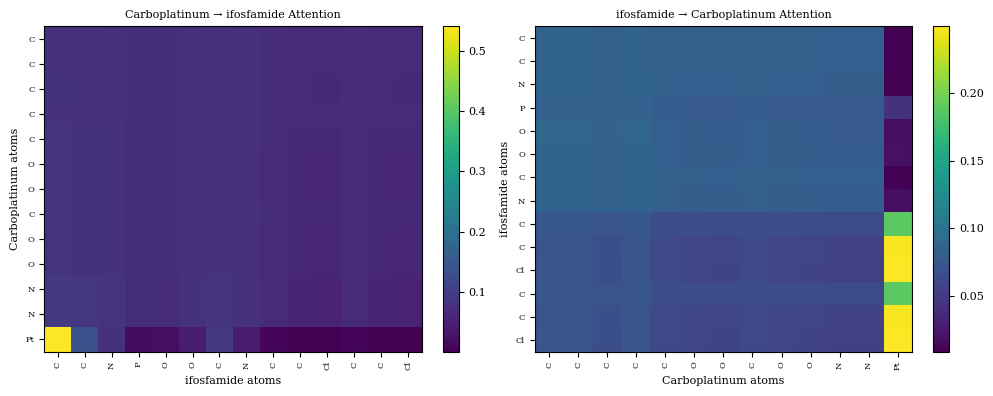

CV of gradient saliency: Carboplatinum = 0.354 | ifosfamide = 1.223


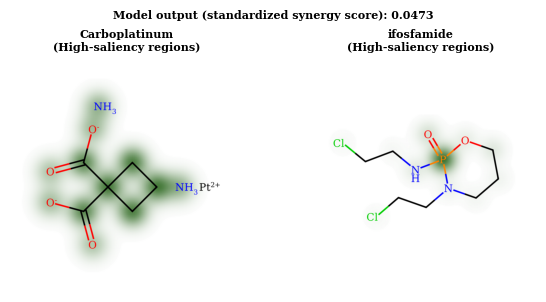

In [ ]:
# ===== Cell 20: Figures 4 and 5 =====
def draw_saliency_on_molecule(smiles, weights, ax, title, scale=3, grid_res=0.02):
    mol = rdMolDraw2D.PrepareMolForDrawing(Chem.MolFromSmiles(smiles), addChiralHs=False)
    if not mol.GetNumConformers():
        rdDepictor.Compute2DCoords(mol)
    conf = mol.GetConformer()
    if mol.GetNumBonds() > 0:                                  # same sigma rule as RDKit's SimilarityMaps
        b = mol.GetBondWithIdx(0)
        sigma = 0.3 * (conf.GetAtomPosition(b.GetBeginAtomIdx()) - conf.GetAtomPosition(b.GetEndAtomIdx())).Length()
    else:
        sigma = 0.3 * (conf.GetAtomPosition(0) - conf.GetAtomPosition(1)).Length()
    sigma = round(sigma, 2)
    locs = [Geometry.Point2D(conf.GetAtomPosition(i).x, conf.GetAtomPosition(i).y) for i in range(mol.GetNumAtoms())]

    drawer = rdMolDraw2D.MolDraw2DCairo(300 * scale, 300 * scale)
    opts = drawer.drawOptions()
    opts.clearBackground = False
    opts.minFontSize, opts.maxFontSize = 6 * scale, 40 * scale
    opts.bondLineWidth = 2 * scale
    if hasattr(opts, "fontFile"):
        opts.fontFile = FIG_FONT_FILE                         # same font for atom labels inside the molecule image
    drawer.ClearDrawing()
    params = Draw.ContourParams()
    params.fillGrid = True
    params.gridResolution = grid_res
    params.extraGridPadding = 0.5
    Draw.ContourAndDrawGaussians(drawer, locs, [float(w) for w in weights], [sigma] * mol.GetNumAtoms(),
                                 nContours=0, params=params)
    drawer.SetLineWidth(2 * scale)                            # the map drawing above reset it to 1
    drawer.DrawMolecule(mol)
    drawer.FinishDrawing()
    ax.imshow(Image.open(io.BytesIO(drawer.GetDrawingText())))
    ax.set_title(title, weight="bold")
    ax.axis("off")

def save_saliency_csv(drug_name, smiles, normalized, raw):
    mol = Chem.MolFromSmiles(smiles)
    df = pd.DataFrame({"drug": drug_name, "atom_idx": range(mol.GetNumAtoms()),
                       "symbol": [a.GetSymbol() for a in mol.GetAtoms()],
                       "atomic_num": [a.GetAtomicNum() for a in mol.GetAtoms()],
                       "importance_normalized": normalized.astype(float), "importance_raw": raw.astype(float)})
    df.to_csv(OUT_DIR / f"saliency_{re.sub(r'[^A-Za-z0-9._-]+', '_', drug_name)}.csv", index=False)


def figure_gradient_saliency(model, drug1_name, drug2_name, cell_line_name, out_stem):
    graphs = make_pair_graphs(drug1_name, drug2_name, cell_line_name)
    if graphs is None:
        return
    sal1, sal2, score = gradient_saliency(model, *graphs)
    print(f"CV of gradient saliency: {drug1_name} = {coefficient_of_variation(sal1):.3f} | "
          f"{drug2_name} = {coefficient_of_variation(sal2):.3f}")
    for name, sal in ((drug1_name, sal1), (drug2_name, sal2)):
        save_saliency_csv(name, drug_to_smiles[name], minmax(sal), sal)
    fig, axes = plt.subplots(1, 2, figsize=(6, 3))
    draw_saliency_on_molecule(drug_to_smiles[drug1_name], minmax(sal1), axes[0], f"{drug1_name}\n(High-saliency regions)")
    draw_saliency_on_molecule(drug_to_smiles[drug2_name], minmax(sal2), axes[1], f"{drug2_name}\n(High-saliency regions)")
    fig.suptitle(f"Model output (standardized synergy score): {score:.4f}", weight="bold", y=0.98)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{out_stem}.png", dpi=FIG_DPI, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{out_stem}.pdf", bbox_inches="tight")
    plt.show()


def figure_cross_attention(model, drug1_name, drug2_name, cell_line_name, out_stem):
    graphs = make_pair_graphs(drug1_name, drug2_name, cell_line_name)
    if graphs is None:
        return
    attn_1to2, attn_2to1, _ = cross_attention_maps(model, *graphs)
    labels1 = [a.GetSymbol() for a in Chem.MolFromSmiles(drug_to_smiles[drug1_name]).GetAtoms()]
    labels2 = [a.GetSymbol() for a in Chem.MolFromSmiles(drug_to_smiles[drug2_name]).GetAtoms()]
    print(f"Attention peakedness (1.0 = uniform): {drug1_name}->{drug2_name} {attention_peakedness(attn_1to2):.2f} | "
          f"{drug2_name}->{drug1_name} {attention_peakedness(attn_2to1):.2f}")
    fig, axes = plt.subplots(1, 2, figsize=(10, 4))
    panels = ((attn_1to2, labels1, labels2, drug1_name, drug2_name),
              (attn_2to1, labels2, labels1, drug2_name, drug1_name))
    for ax, (attn, rows, cols, src, dst) in zip(axes, panels):
        im = ax.imshow(attn, cmap="viridis", aspect="auto")
        ax.set_xticks(range(len(cols))); ax.set_xticklabels(cols, fontsize=6, rotation=90)
        ax.set_yticks(range(len(rows))); ax.set_yticklabels(rows, fontsize=6)
        ax.set_xlabel(f"{dst} atoms"); ax.set_ylabel(f"{src} atoms")
        ax.set_title(f"{src} → {dst} Attention")
        plt.colorbar(im, ax=ax, fraction=0.046)
    fig.tight_layout()
    fig.savefig(FIG_DIR / f"{out_stem}.png", dpi=FIG_DPI, bbox_inches="tight")
    fig.savefig(FIG_DIR / f"{out_stem}.pdf", bbox_inches="tight")
    plt.show()


CASE = ("Carboplatinum", "ifosfamide", "HS 578T")
for name in CASE[:2]:
    where = "TEST" if name in xai_fold["test_drugs"] else "validation" if name in xai_fold["val_drugs"] else "training"
    print(f"{name}: {where} compound of the fold-{best_fold_num} model")
in_test = {CASE[0], CASE[1]} & set(xai_fold["test_drugs"])
print("✓ both compounds are training/validation compounds of this model (as stated in the paper)" if not in_test
      else f"⚠ test compound(s) of this fold: {in_test} -> the sentence in the paper must be updated")

figure_cross_attention(xai_model, *CASE, out_stem="Fig4_CrossAttention_Heatmap")
figure_gradient_saliency(xai_model, *CASE, out_stem="Fig5_Gradient_Saliency")

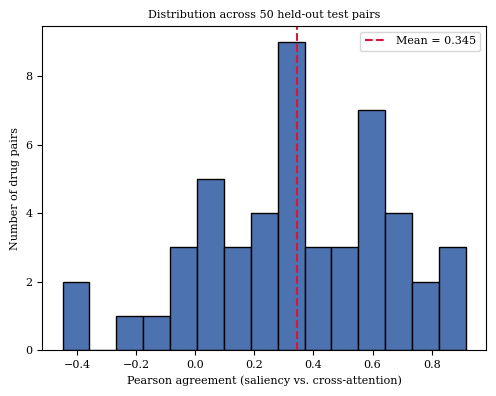

In [ ]:
# ===== Cell 21: Distribution of the agreement scores =====
fig, ax = plt.subplots(figsize=(5, 4))
ax.hist(agreement_scores, bins=15, color="#4C72B0", edgecolor="black")
ax.axvline(agreement_scores.mean(), color="crimson", linestyle="--", label=f"Mean = {agreement_scores.mean():.3f}")
ax.set(xlabel="Pearson agreement (saliency vs. cross-attention)", ylabel="Number of drug pairs",
       title=f"Distribution across {len(agreement_scores)} held-out test pairs")
ax.legend()
fig.tight_layout()
fig.savefig(FIG_DIR / "Agreement_Distribution.png", dpi=FIG_DPI, bbox_inches="tight")
plt.show()